# 61 — Verbal aggression: illustration and agreement (paper Section 6.1, bucket 1)

This notebook is the code of Section 6.1. It fits De Boeck and Partchev's (2012) linear tree to the verbal aggression data with four models, specified step by step:

| Model | Link | Covariates | Item locations | lme4 counterpart (`61a_lme4_reference.qmd`) |
|---|---|---|---|---|
| **A1** | logit | none | fixed by node (flat prior) | `value ~ 0 + item:node + (0 + node | id)` |
| **B1** | probit | none | fixed by node (flat prior) | the same, probit link |
| **A2** | logit | person (anger, gender) and item (behavior, situation, mode), with a node intercept | random by node | `value ~ 0 + node + node:(covariates) + (0 + node | id) + (0 + d1 + d2 || item)` |
| **B2** | probit | the same | random by node | the same, probit link |

What it shows, in order:
1. **Specification** of the tree, the data, the node models and the priors, each a separate step.
2. **Fits** of the four models through one helper that times them and records their effective sample sizes.
3. **Agreement with lme4** for every model (A1 and A2 against the published-style glmer fits, B1 and B2 against glmer with a probit link).
4. **Probit against logit**: B1 converted with `to_logit()` against A1, item by item, and when the two agree.
5. **Speed**: wall time and effective samples per second, irtree against lme4 (and brms if `check_brms.qmd` was run).
6. **Interpretation** of B1 and B2.
7. **Beyond lme4**: the same tree with discriminations (2PL), which glmer cannot fit, compared with B2 by LOO.

**Before running:** run `61a_lme4_reference.qmd` in RStudio (chunk by chunk, or Render) from this folder; it writes `results/lme4_*.csv`. **Runtime:** every fit is timed; the last cell saves the table to `results/runtime_61.csv`.

## Background

From DeBoeck (2012):

The choice for perhaps" or yes" vs. no" which refers to the top node is about admitting
one may show an aggressive reaction. 

Admission is different from affirmation. The choice for yes" vs. "perhaps" refers to the second node and implies the affirmation of an aggressive
reaction. Admission and affirmation may be two qualitatively different responses and rely on
different latent traits. Affirmation is not necessarily more of the same or just stronger than
admission.

From Jeon & Deboeck, 2016
Recall
that in Fig. 2 the ‘Perhaps’ category is differentiated in Stage
1 instead of in Stage 2. The tree in Fig. 2 is useful for finding
out whether the ‘Perhaps’ response stems from a preliminary
feeling of certainty. The tree in Fig. 3 is more useful
for testing whether the ‘Perhaps’ response is a way to admit
verbal aggression. Based on the model fit, the tree in Fig. 3
(log-likelihood = −6087.22) appears to be a better representation
of the item response process for the data than the
tree in Fig. 2 (log-likelihood=−6188.76).


Based on the tree in Fig. 3, we fit a two-dimensional
item response tree model. The correlation between the two
dimensions is estimated as 0.38. This indicates that the two
decision processes (direction and certainty) are only weakly
correlated, implying that the resulting outcomes of the two
internal processes are not closely related to each other. That
is, the three response categories (‘No’, ‘Perhaps’,‘Yes’) may
not be really ordinal. The response scale seems to be multidimensional,
meaning that a different latent variable is
measured depending on the response option chosen by the
person (also per item).


1) Model 1: a reduced two-dimensional tree model that
includes node-specific main effects parameters (but
not node-specific item slopes and intercepts),

(2) Model 2: a unidimensional tree model that assumes
a single latent variable (but with node-specific item
slopes and intercepts), and


(3) Model 3: a bifactor tree model that assumes a general
latent trait for all response categories in addition to the
latent traits for the two internal nodes. ------------------------->>> This is not yet possible in the package



These results suggest that inference and decision
based on subjects’ latent trait scores can be biased
if non-ordinality of a response scale is ignored in data
analysis.

## Setup

In [2]:
# Install the package from this repository (editable), once per environment.
# After pulling new code, RESTART THE KERNEL so the new version is the one imported.
import sys, pathlib
ROOT = pathlib.Path.cwd().parents[1]
!{sys.executable} -m pip install -q -e "{ROOT}[full]"

In [3]:
import time, contextlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import irtree
from irtree.diagnostics import parse_param_name
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)
print("irtree", irtree.__version__)

RESULTS = pathlib.Path("results"); RESULTS.mkdir(exist_ok=True)

# Runtime log for steps that are not fits (LOO, report, ...).
RUNTIME = []
@contextlib.contextmanager
def timed(step):
    t0 = time.perf_counter(); yield; dt = time.perf_counter() - t0
    RUNTIME.append({"step": step, "seconds": round(dt, 1)})
    print(f"[{step}] " + (f"{dt / 60:.1f} min" if dt >= 60 else f"{dt:.1f} s"))

irtree 0.4.0


## Settings
`N_ITER` counts warm-up and retained draws per chain. `N_CHAINS` chains run in parallel processes. `VAGUE`, a nearly flat N(0, 10), stands in for "no prior" wherever irtree is compared with a maximum-likelihood fixed effect.

In [4]:
N_ITER   = 4000
N_CHAINS = 4
SEED     = 2026
VAGUE    = irtree.NormalPrior(mean=0.0, variance=10.0)
STRUCTURAL = ("sigma2", "rho", "b.variance", "beta", "kappa")   # kinds summarized and timed
print(f"N_ITER={N_ITER}  N_CHAINS={N_CHAINS}  SEED={SEED}")

N_ITER=4000  N_CHAINS=4  SEED=2026


## Helpers
`run_fit` fits one model from its specification (data, node models, priors), times it, and records the run: wall time, retained draws, and the smallest bulk effective sample size among the structural parameters (variances, correlation, coefficients). The specification itself stays in its own steps below. `structural` returns the posterior summary of the structural parameters.

In [5]:
FITS, RUNS = {}, []

def run_fit(label, data, nodes, priors, n_chains=N_CHAINS, n_iter=N_ITER, seed=SEED):
    """Fit one specified model, time it, and record the run under `label`."""
    t0 = time.perf_counter()
    fit = irtree.irtree_fit(data, spec, nodes, priors=priors, n_iter=n_iter,
                            n_chains=n_chains, seed=seed, progress=False)
    seconds = time.perf_counter() - t0
    params = fit.diagnostics().params
    struct = params[params["kind"].isin(STRUCTURAL)]
    draws = sum(r.chain.shape[0] for r in fit.results)
    RUNS.append({"model": label, "software": "irtree", "chains": n_chains, "iterations": n_iter,
                 "draws": draws, "seconds": round(seconds, 1),
                 "min_ess_structural": round(struct["ess_bulk"].min()),
                 "ess_per_second": round(struct["ess_bulk"].min() / seconds, 1)})
    FITS[label] = fit
    print(f"[{label}] {seconds:.1f} s, {draws} draws, smallest structural ESS {struct['ess_bulk'].min():.0f}")
    return fit

def structural(fit, kinds=STRUCTURAL, cols=("mean", "sd", "hdi_lo", "hdi_hi", "n_eff")):
    s = fit.summary_df()
    keep = [n for n in s.index if parse_param_name(n)["kind"] in kinds]
    return s.loc[keep, list(cols)]

def compare(rows, label):
    """irtree posterior mean / SD against a reference estimate / SE."""
    df = pd.DataFrame(rows, columns=["parameter", "irtree_mean", "irtree_sd", "ref_est", "ref_se"])
    df["diff"] = df["irtree_mean"] - df["ref_est"]
    df["diff_in_se"] = df["diff"] / df["ref_se"]
    print(f"{label}: {len(df)} parameters, max |diff| = {df['diff'].abs().max():.3f}, "
          f"max |diff|/SE = {df['diff_in_se'].abs().max():.2f}, "
          f"corr = {np.corrcoef(df['irtree_mean'], df['ref_est'])[0, 1]:.4f}")
    return df

def scatter(df, title, ax, x="ref_est", y="irtree_mean", xlabel="lme4 estimate", ylabel="irtree posterior mean"):
    lo, hi = df[[x, y]].min().min(), df[[x, y]].max().max()
    ax.plot([lo, hi], [lo, hi], color="0.7", lw=1)
    ax.plot(df[x], df[y], "o", ms=3)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)

## Step 1: Declare the tree
The linear tree has two nodes. Node 1 separates *no* from *perhaps or yes* (admission); node 2, reached only by *perhaps or yes*, separates *perhaps* from *yes* (affirmation). Rows of the mapping matrix are the categories 0, 1, 2; `NaN` marks a node that is not on the path.

In [6]:
spec = irtree.IRTreeSpec(mapping=np.array([[0, np.nan],    # no
                                           [1, 0],         # perhaps
                                           [1, 1]]),       # yes
                         category_names=("no", "perhaps", "yes"),
                         node_names=("admission", "affirmation"))
spec

IRTreeSpec(K=3, R=2, latent_dims=2)
  Categories:        K = 3
  Nodes:             R = 2
  Latent dimensions: 2
  Outcomes per node: [2, 2]

## Step 2: Prepare the data
### Step 2.1: Read the data
One row per person × item. The responses are recoded to 0 (no), 1 (perhaps), 2 (yes).

In [7]:
va = pd.read_csv("verbagg_long.csv")
va["response"] = va["resp"].map({"no": 0, "perhaps": 1, "yes": 2})
print(va.shape)
print(va["resp"].value_counts())
va.head()

(7584, 9)
resp
no         3973
perhaps    2081
yes        1530
Name: count, dtype: int64


,id,item,resp,Anger,Gender,btype,situ,mode,response
0,1,S1WantCurse,no,20,M,curse,other,want,0
1,2,S1WantCurse,no,11,M,curse,other,want,0
2,3,S1WantCurse,perhaps,17,F,curse,other,want,1
3,4,S1WantCurse,perhaps,21,F,curse,other,want,1
4,5,S1WantCurse,perhaps,17,F,curse,other,want,1


In [8]:
va[va["id"] == 1]      # one person's 24 responses

,id,item,resp,Anger,Gender,btype,situ,mode,response
0,1,S1WantCurse,no,20,M,curse,other,want,0
316,1,S1WantScold,no,20,M,scold,other,want,0
632,1,S1WantShout,no,20,M,shout,other,want,0
948,1,S2WantCurse,no,20,M,curse,other,want,0
1264,1,S2WantScold,no,20,M,scold,other,want,0
1580,1,S2WantShout,no,20,M,shout,other,want,0
1896,1,S3WantCurse,no,20,M,curse,self,want,0
2212,1,S3WantScold,no,20,M,scold,self,want,0
2528,1,S3WantShout,perhaps,20,M,shout,self,want,1
2844,1,S4wantCurse,yes,20,M,curse,self,want,2


### Step 2.2: Covariates
Covariates are entered on their raw scale and transformed when the data are loaded (Step 2.3).

* person: `anger` (Anger score) and `male` (gender indicator);
* item: `scold`, `shout` (curse is the reference), `self` (self to blame), `do` (doing rather than wanting), and `intercept`, a column of ones.

**Why an intercept, and what centering does then.** irtree fixes the trait mean at 0 and the prior mean of the item locations at 0. One of the two is enough to fix the origin of a dimension, so with both the node's overall level has no parameter of its own. Without an intercept, that level is carried by the item locations (inflating their variance) and by any uncentered coefficient, through its covariate's mean; an item coefficient, pinned by only 24 items, can be noticeably biased (identification paper; notebook `31_location_and_centering`). The intercept gives the level its own parameter. With it, centering no longer changes the coefficients; it only makes the intercept the node's level at the average person and item. We center all covariates and scale `anger` (its unit, a point on the Anger scale, is arbitrary); the indicators stay in their natural unit, so their coefficients compare two categories.

In [9]:
pers  = va.drop_duplicates("id")
items = va.drop_duplicates("item")

person_cov = pd.DataFrame({"id":    pers["id"],
                           "anger": pers["Anger"].astype(float),
                           "male":  (pers["Gender"] == "M").astype(float)})

item_cov = pd.DataFrame({"item":      items["item"],
                         "intercept": 1.0,
                         "scold":     (items["btype"] == "scold").astype(float),
                         "shout":     (items["btype"] == "shout").astype(float),
                         "self":      (items["situ"] == "self").astype(float),
                         "do":        (items["mode"] == "do").astype(float)})

table = va[["id", "item", "response"]].merge(person_cov, on="id").merge(item_cov, on="item")
X_NAMES = ["anger", "male"]
Q_NAMES = ["intercept", "scold", "shout", "self", "do"]
table.head()

,id,item,response,anger,male,intercept,scold,shout,self,do
0,1,S1WantCurse,0,20.0,1.0,1.0,0.0,0.0,0.0,0.0
1,2,S1WantCurse,0,11.0,1.0,1.0,0.0,0.0,0.0,0.0
2,3,S1WantCurse,1,17.0,0.0,1.0,0.0,0.0,0.0,0.0
3,4,S1WantCurse,1,21.0,0.0,1.0,0.0,0.0,0.0,0.0
4,5,S1WantCurse,1,17.0,0.0,1.0,0.0,0.0,0.0,0.0


### Step 2.3: Load the data
`load_data` in single-table mode: the long table carries the responses and both kinds of covariates; `roles` says which columns are person (X) and item (Q) covariates. It aligns everything by person and item id and expands the responses into the pseudo-item responses of each node. `center=True` centers every non-constant covariate (the intercept column is left as it is); `scale={"X": ["anger"]}` scales `anger` only.

Two prepared data sets: with covariates (models A2, B2) and without (A1, B1).

In [12]:
data_cov = irtree.load_data(table, spec=spec, person_id="id", item_id="item",
                            response_col="response", roles={"X": X_NAMES, "Q": Q_NAMES},
                            categories_start=0, center=True, scale={"X": ["anger"]})
print(irtree.summarize_prepared(data_cov, spec))

Ingest: P=316 persons, I=24 items (first-seen order).
  X:  Centered: ['anger', 'male']
  X:  Scaled: ['anger']; unchanged: ['male']
  Q:  Centered: ['scold', 'shout', 'self', 'do']; unchanged: ['intercept']
PreparedData: P=316, I=24, R=2, missing=0
  Node 1: n_relevant=7584, mean_Y*=0.476
  Node 2: n_relevant=3611, mean_Y*=0.424
  X (person covariates): K_x=2, n_missing=0
  Q (item covariates): K_q=5, n_missing=0


In [13]:
data_nocov = irtree.load_data(table[["id", "item", "response"]], spec=spec, person_id="id",
                              item_id="item", response_col="response", categories_start=0,
                              verbose=False)
print(irtree.summarize_prepared(data_nocov, spec))

PreparedData: P=316, I=24, R=2, missing=0
  Node 1: n_relevant=7584, mean_Y*=0.476
  Node 2: n_relevant=3611, mean_Y*=0.424


## Step 3: Node models and priors
Each model is specified in its own cell: node models first, then priors (the package defaults, printed by `priors.summary()`, with the changes stated).

* **A1, B1 (no covariates, items fixed).** The item locations get the flat `VAGUE` prior, so they act as the fixed effects of De Boeck and Partchev's model; trait variances (Rasch dimensions) and the correlation keep their defaults (inverse-gamma(1, 1); LKJ(1)).
* **A2, B2 (covariates, items random).** The item locations keep their default hierarchical prior; the coefficients get `VAGUE`, because the default hierarchical prior on coefficients would shrink the intercept and the indicator effects toward each other through a shared variance estimated from five values.

### Step 3.1: A1, logit, no covariates

In [14]:
nodes_A1 = [irtree.LogitRaschNode(), irtree.LogitRaschNode()]
priors_A1 = irtree.build_default_priors(spec, nodes_A1)
priors_A1.set("b", VAGUE)
priors_A1.summary()


TABLE 1 — Main parameters
──────────────────────────────────────────────────────────────────────────────────────────────────────────
Parameter       Node 1                                        Node 2                                      
──────────────────────────────────────────────────────────────────────────────────────────────────────────
theta           Normal(0.0, [estimated~InvGammaPrior] theta.variance) [2]  Normal(0.0, [estimated~InvGammaPrior] theta.variance) [2]
──────────────────────────────────────────────────────────────────────────────────────────────────────────
b               Normal(0.0, 10.0) [2]                         Normal(0.0, 10.0) [2]                       
──────────────────────────────────────────────────────────────────────────────────────────────────────────
a               —                                             —                                           
───────────────────────────────────────────────────────────────────────────────────────────

### Step 3.2: B1, probit, no covariates

In [15]:
nodes_B1 = [irtree.ProbitRaschNode(), irtree.ProbitRaschNode()]
priors_B1 = irtree.build_default_priors(spec, nodes_B1)
priors_B1.set("b", VAGUE)

### Step 3.3: A2, logit, with covariates

In [16]:
nodes_A2 = [irtree.LogitRaschNode(person_covariates=True, item_covariates=True),
            irtree.LogitRaschNode(person_covariates=True, item_covariates=True)]
priors_A2 = irtree.build_default_priors(spec, nodes_A2)
priors_A2.set("beta", VAGUE)
priors_A2.set("kappa", VAGUE)
priors_A2.summary()


TABLE 1 — Main parameters
──────────────────────────────────────────────────────────────────────────────────────────────────────────
Parameter       Node 1                                        Node 2                                      
──────────────────────────────────────────────────────────────────────────────────────────────────────────
theta           Normal(0.0, [estimated~InvGammaPrior] theta.variance) [2]  Normal(0.0, [estimated~InvGammaPrior] theta.variance) [2]
──────────────────────────────────────────────────────────────────────────────────────────────────────────
b               Normal(0.0, [estimated~InvGammaPrior] b.variance) [2]  Normal(0.0, [estimated~InvGammaPrior] b.variance) [2]
──────────────────────────────────────────────────────────────────────────────────────────────────────────
a               —                                             —                                           
─────────────────────────────────────────────────────────────────────────

### Step 3.4: B2, probit, with covariates

In [17]:
nodes_B2 = [irtree.ProbitRaschNode(person_covariates=True, item_covariates=True),
            irtree.ProbitRaschNode(person_covariates=True, item_covariates=True)]
priors_B2 = irtree.build_default_priors(spec, nodes_B2)
priors_B2.set("beta", VAGUE)
priors_B2.set("kappa", VAGUE)

## Step 4: Fit
One call per model. Probit nodes are drawn exactly, apart from the correlation (one Metropolis-Hastings step); logit nodes use Metropolis-Hastings throughout, so they are slower per iteration.

In [20]:
fit_A1 = run_fit("A1", data_nocov, nodes_A1, priors_A1, n_chains=1)


irtree fit complete  (1 chain × 4000 iterations, 3600 posterior draws)
   parameters: 677 PASS · 6 WARN · 0 FAIL   (of 683)
   3 flagged only for under-warmup — resolve by discarding the first ~10% (recommended_burnin).
   (overall label is advisory; the per-parameter table is the decision. Call fit.diagnostics().)
   status key:
     PASS (converged): stationary with no burn-in needed, adequate mixing.
     WARN (usable, but check): at worst under-warmed (a recommended burn-in is given), OR the two stationarity tests (Geweke & Heidelberger-Welch) disagree (one passes, one flags), OR mixing/precision is marginal (low ESS, high MCSE, R-hat slightly > 1).
     FAIL (did not converge): fails BOTH stationarity tests (Geweke & Heidelberger-Welch), or R-hat exceeds its hard threshold. A parameter that passes EITHER stationarity test is a WARN, not a FAIL.
⚠  Single chain — R-hat unavailable. Stationarity via Geweke + Heidelberger-Welch.
✓ Stationarity (Geweke):   All Geweke within threshold

In [21]:
fit_B1 = run_fit("B1", data_nocov, nodes_B1, priors_B1, n_chains=1)


irtree fit complete  (1 chain × 4000 iterations, 3600 posterior draws)
   parameters: 666 PASS · 17 WARN · 0 FAIL   (of 683)
   5 flagged only for under-warmup — resolve by discarding the first ~10% (recommended_burnin).
   (overall label is advisory; the per-parameter table is the decision. Call fit.diagnostics().)
   status key:
     PASS (converged): stationary with no burn-in needed, adequate mixing.
     WARN (usable, but check): at worst under-warmed (a recommended burn-in is given), OR the two stationarity tests (Geweke & Heidelberger-Welch) disagree (one passes, one flags), OR mixing/precision is marginal (low ESS, high MCSE, R-hat slightly > 1).
     FAIL (did not converge): fails BOTH stationarity tests (Geweke & Heidelberger-Welch), or R-hat exceeds its hard threshold. A parameter that passes EITHER stationarity test is a WARN, not a FAIL.
⚠  Single chain — R-hat unavailable. Stationarity via Geweke + Heidelberger-Welch.
✓ Stationarity (Geweke):   All Geweke within threshol

In [22]:
fit_A2 = run_fit("A2", data_cov, nodes_A2, priors_A2, n_chains=1)


irtree fit complete  (1 chain × 4000 iterations, 3600 posterior draws)
   parameters: 690 PASS · 9 WARN · 0 FAIL   (of 699)
   2 flagged only for under-warmup — resolve by discarding the first ~10% (recommended_burnin).
   (overall label is advisory; the per-parameter table is the decision. Call fit.diagnostics().)
   status key:
     PASS (converged): stationary with no burn-in needed, adequate mixing.
     WARN (usable, but check): at worst under-warmed (a recommended burn-in is given), OR the two stationarity tests (Geweke & Heidelberger-Welch) disagree (one passes, one flags), OR mixing/precision is marginal (low ESS, high MCSE, R-hat slightly > 1).
     FAIL (did not converge): fails BOTH stationarity tests (Geweke & Heidelberger-Welch), or R-hat exceeds its hard threshold. A parameter that passes EITHER stationarity test is a WARN, not a FAIL.
⚠  Single chain — R-hat unavailable. Stationarity via Geweke + Heidelberger-Welch.
✓ Stationarity (Geweke):   All Geweke within threshold

In [23]:
fit_B2 = run_fit("B2", data_cov, nodes_B2, priors_B2, n_chains=1)


irtree fit complete  (1 chain × 4000 iterations, 3600 posterior draws)
   parameters: 687 PASS · 12 WARN · 0 FAIL   (of 699)
   1 flagged only for under-warmup — resolve by discarding the first ~10% (recommended_burnin).
   (overall label is advisory; the per-parameter table is the decision. Call fit.diagnostics().)
   status key:
     PASS (converged): stationary with no burn-in needed, adequate mixing.
     WARN (usable, but check): at worst under-warmed (a recommended burn-in is given), OR the two stationarity tests (Geweke & Heidelberger-Welch) disagree (one passes, one flags), OR mixing/precision is marginal (low ESS, high MCSE, R-hat slightly > 1).
     FAIL (did not converge): fails BOTH stationarity tests (Geweke & Heidelberger-Welch), or R-hat exceeds its hard threshold. A parameter that passes EITHER stationarity test is a WARN, not a FAIL.
⚠  Single chain — R-hat unavailable. Stationarity via Geweke + Heidelberger-Welch.
✓ Stationarity (Geweke):   All Geweke within threshol

## Step 5: Convergence
`diagnostics()` displays one row per parameter kind; `.params` has one row per parameter and `.flagged` the parameters that need attention, with the reason.

In [24]:
for label, fit in FITS.items():
    print(f"\n=== {label}"); display(fit.diagnostics())


=== A1


,n,n_pass,n_warn,n_fail,max_rhat,min_ess_bulk,min_ess_tail,max_mcse_sd
kind,,,,,,,,
theta,632,629,3,0,,359,421,0.053
b,48,47,1,0,,570,859,0.042
sigma2,2,1,1,0,,209,888,0.069
rho,1,0,1,0,,234,550,0.065



=== B1


,n,n_pass,n_warn,n_fail,max_rhat,min_ess_bulk,min_ess_tail,max_mcse_sd
kind,,,,,,,,
theta,632,617,15,0,,296,688,0.058
b,48,48,0,0,,432,1123,0.048
sigma2,2,1,1,0,,385,1381,0.051
rho,1,0,1,0,,336,522,0.055



=== A2


,n,n_pass,n_warn,n_fail,max_rhat,min_ess_bulk,min_ess_tail,max_mcse_sd
kind,,,,,,,,
theta,632,625,7,0,,363,517,0.053
b,48,48,0,0,,992,1497,0.032
sigma2,2,1,1,0,,294,1106,0.058
b.variance,2,2,0,0,,1014,2720,0.031
rho,1,0,1,0,,256,581,0.062
beta,4,4,0,0,,1245,2819,0.028
kappa,10,10,0,0,,871,2585,0.034



=== B2


,n,n_pass,n_warn,n_fail,max_rhat,min_ess_bulk,min_ess_tail,max_mcse_sd
kind,,,,,,,,
theta,632,622,10,0,,248,720,0.063
b,48,48,0,0,,1196,2612,0.029
sigma2,2,1,1,0,,398,1170,0.050
b.variance,2,2,0,0,,2017,3077,0.022
rho,1,0,1,0,,245,609,0.064
beta,4,4,0,0,,1212,2957,0.029
kappa,10,10,0,0,,1789,2768,0.024


In [25]:
fit_A2.diagnostics().flagged.head(10)

,reason,kind,node,index,sub,rhat,ess_bulk,ess_tail,mcse,mcse_sd,...,geweke_p,geweke_status,geweke_burnin,hw_passed,hw_n_discarded,acf_1,acf_5,acf_10,acf_50,status
param,,,,,,,,,,,,,,,,,,,,,
rho_1_2,bulk ESS 256 < 400,rho,1_2,None,None,NaN,256.491143,581.153240,0.004528,0.062440,...,0.440975,converged,0.0,True,0.0,0.830032,0.467142,0.228954,-0.047839,WARN
sigma2_2,bulk ESS 294 < 400,sigma2,2,None,None,NaN,294.117094,1105.789913,0.012454,0.058310,...,0.962633,converged,0.0,True,0.0,0.625522,0.365797,0.181196,-0.005042,WARN
theta_1_238,Geweke: discard first 10%,theta,1,238,None,NaN,759.837370,887.029635,0.018772,0.036278,...,0.000613,converged_after_burnin,0.1,True,360.0,0.595615,0.089498,0.026538,-0.014741,WARN
theta_2_9,Heidelberger-Welch failed,theta,2,9,None,NaN,680.539756,786.028324,0.025633,0.038333,...,0.597310,converged,0.0,False,NaN,0.618371,0.093859,0.048711,0.003810,WARN
theta_2_74,Heidelberger-Welch failed,theta,2,74,None,NaN,595.952774,1052.419994,0.035546,0.040963,...,0.272432,converged,0.0,False,NaN,0.673958,0.115846,0.003293,-0.004919,WARN
theta_2_133,bulk ESS 363 < 400,theta,2,133,None,NaN,362.697456,791.860633,0.039137,0.052508,...,0.897194,converged,0.0,True,0.0,0.625892,0.117533,0.054274,0.071995,WARN
theta_2_218,Geweke: discard first 10%,theta,2,218,None,NaN,937.516560,1095.722489,0.016798,0.032660,...,0.000579,converged_after_burnin,0.1,True,0.0,0.588459,0.054853,-0.018348,0.021552,WARN
theta_2_226,Heidelberger-Welch failed,theta,2,226,None,NaN,809.124025,882.054923,0.020425,0.035155,...,0.029249,converged,0.0,False,NaN,0.608431,0.032121,0.011375,-0.013818,WARN
theta_2_265,Heidelberger-Welch failed,theta,2,265,None,NaN,824.204742,996.336354,0.019782,0.034832,...,0.524025,converged,0.0,False,NaN,0.613684,0.117039,-0.007793,-0.008568,WARN


## Step 6: Agreement with lme4
The lme4 estimates come from `61a_lme4_reference.qmd` (glmer, Laplace approximation). glmer's coefficient of `item:node` is −b. With 316 × 24 responses and flat priors on the fixed effects, posterior means should be close to the maximum-likelihood estimates and posterior SDs close to the standard errors. Two systematic differences are expected and are not errors: a variance estimated from few units (the 24 item locations of a node in A2, B2) is pulled by its prior and is right-skewed, so its posterior mean exceeds its ML estimate; and glmer's standard errors treat the variance components as known, so they are smaller than posterior SDs.

In [27]:
lme4 = {m: pd.read_csv(RESULTS / f"lme4_{m}.csv").set_index("term") for m in ("A1", "B1", "A2", "B2")}
ITEMS = list(data_nocov.item_ids)
NODE = {1: "n1", 2: "n2"}

def agree_items_fixed(m):
    s, ref = FITS[m].summary_df(), lme4[m]
    rows = [(f"b_{r}_{i + 1}", -s.loc[f"b_{r}_{i + 1}", "mean"], s.loc[f"b_{r}_{i + 1}", "sd"],
             ref.loc[f"item{it}:node{NODE[r]}", "estimate"], ref.loc[f"item{it}:node{NODE[r]}", "se"])
            for r in (1, 2) for i, it in enumerate(ITEMS)]
    loc = compare(rows, f"{m}, item locations (as -b)")
    vc = pd.DataFrame({"irtree_mean": s.loc[["sigma2_1", "sigma2_2", "rho_1_2"], "mean"],
                       "irtree_sd": s.loc[["sigma2_1", "sigma2_2", "rho_1_2"], "sd"],
                       "lme4": ref.loc[["var_id_noden1", "var_id_noden2", "cor_id_noden1_noden2"], "estimate"].to_numpy()})
    return loc, vc

cmp_A1, vc_A1 = agree_items_fixed("A1"); display(vc_A1.round(3))
cmp_B1, vc_B1 = agree_items_fixed("B1"); display(vc_B1.round(3))

A1, item locations (as -b): 48 parameters, max |diff| = 0.036, max |diff|/SE = 0.14, corr = 1.0000


,irtree_mean,irtree_sd,lme4
param,,,
sigma2_1,1.957,0.200,1.919
sigma2_2,1.918,0.263,1.821
rho_1_2,0.378,0.070,0.392


B1, item locations (as -b): 48 parameters, max |diff| = 0.028, max |diff|/SE = 0.14, corr = 1.0000


,irtree_mean,irtree_sd,lme4
param,,,
sigma2_1,0.672,0.067,0.664
sigma2_2,0.687,0.087,0.650
rho_1_2,0.382,0.067,0.398


In [28]:
def glmer_term(name):
    kind, r, cov = name.split("_", 2)
    return f"node{NODE[int(r)]}" if cov == "intercept" else f"node{NODE[int(r)]}:{cov}"

VC_COV = {"sigma2_1": "var_id_noden1", "sigma2_2": "var_id_noden2", "rho_1_2": "cor_id_noden1_noden2",
          "b.variance_1": "var_item_d1", "b.variance_2": "var_item.1_d2"}

def agree_covariates(m):
    s, ref = FITS[m].summary_df(), lme4[m]
    coefs = [n for n in s.index if n.startswith(("beta_", "kappa_"))]
    rows = [(n, s.loc[n, "mean"], s.loc[n, "sd"], ref.loc[glmer_term(n), "estimate"],
             ref.loc[glmer_term(n), "se"]) for n in coefs]
    cf = compare(rows, f"{m}, coefficients")
    vc = pd.DataFrame({"irtree_mean": s.loc[list(VC_COV), "mean"], "irtree_median": s.loc[list(VC_COV), "q50"],
                       "irtree_sd": s.loc[list(VC_COV), "sd"],
                       "lme4": ref.loc[list(VC_COV.values()), "estimate"].to_numpy()})
    return cf, vc

cmp_A2, vc_A2 = agree_covariates("A2"); display(cmp_A2.round(3)); display(vc_A2.round(3))
cmp_B2, vc_B2 = agree_covariates("B2"); display(vc_B2.round(3))

A2, coefficients: 14 parameters, max |diff| = 0.032, max |diff|/SE = 0.33, corr = 0.9998


,parameter,irtree_mean,irtree_sd,ref_est,ref_se,diff,diff_in_se
0,beta_1_anger,0.285,0.082,0.280,0.082,0.005,0.059
1,beta_1_male,0.319,0.194,0.321,0.192,-0.003,-0.013
2,beta_2_anger,0.503,0.086,0.496,0.083,0.007,0.085
3,beta_2_male,0.355,0.195,0.349,0.192,0.006,0.032
4,kappa_1_intercept,-0.161,0.139,-0.158,0.107,-0.003,-0.024
5,kappa_1_scold,-1.042,0.271,-1.059,0.184,0.018,0.096
6,kappa_1_shout,-2.097,0.276,-2.104,0.187,0.007,0.038
7,kappa_1_self,-1.053,0.220,-1.054,0.151,0.001,0.009
8,kappa_1_do,-0.711,0.224,-0.707,0.151,-0.004,-0.029
9,kappa_2_intercept,-0.951,0.138,-0.919,0.097,-0.032,-0.331


,irtree_mean,irtree_median,irtree_sd,lme4
param,,,,
sigma2_1,1.875,1.864,0.189,1.806
sigma2_2,1.629,1.622,0.214,1.509
rho_1_2,0.338,0.339,0.073,0.345
b.variance_1,0.279,0.259,0.101,0.117
b.variance_2,0.244,0.227,0.092,0.043


B2, coefficients: 14 parameters, max |diff| = 0.026, max |diff|/SE = 0.35, corr = 0.9997


,irtree_mean,irtree_median,irtree_sd,lme4
param,,,,
sigma2_1,0.646,0.643,0.064,0.624
sigma2_2,0.588,0.583,0.078,0.535
rho_1_2,0.335,0.338,0.071,0.349
b.variance_1,0.166,0.155,0.057,0.040
b.variance_2,0.164,0.154,0.057,0.015


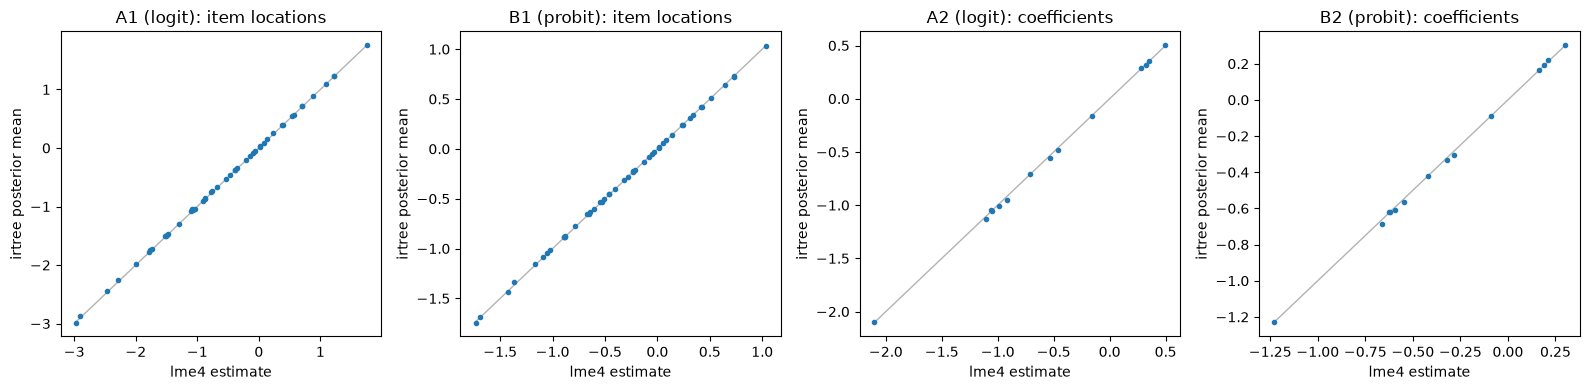

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
scatter(cmp_A1, "A1 (logit): item locations", axes[0])
scatter(cmp_B1, "B1 (probit): item locations", axes[1])
scatter(cmp_A2, "A2 (logit): coefficients", axes[2])
scatter(cmp_B2, "B2 (probit): coefficients", axes[3])
fig.tight_layout(); fig.savefig(RESULTS / "agreement_lme4.png", dpi=200)
for name, df in {"A1": cmp_A1, "B1": cmp_B1, "A2": cmp_A2, "B2": cmp_B2}.items():
    df.to_csv(RESULTS / f"agreement_lme4_{name}.csv", index=False)

## Step 7: Probit against logit
**Premise.** Φ(x) ≈ L(1.702 x), so a probit model and a logit model of the same data should agree after rescaling: on these Rasch dimensions (no discriminations, trait variance estimated) `to_logit()` multiplies the traits, locations and coefficients by 1.702 and the variances by 1.702²; the correlation is scale-free and unchanged.

**Prediction.** The correlation agrees exactly (up to Monte Carlo error); variances and locations agree up to the quality of the approximation, which is best in the middle of the distribution and worst in the tails, where the logistic has heavier tails than the normal. So the gap between converted probit and logit locations should grow with how extreme an item is.

The same comparison on the lme4 fits (logit A1 against probit B1) separates a property of the links from a property of the software.

In [30]:
lg_B1 = fit_B1.to_logit()
s_A1 = fit_A1.summary_df()
q = ["sigma2_1", "sigma2_2", "rho_1_2"]
link_vc = pd.DataFrame({"A1 logit": s_A1.loc[q, "mean"], "B1 probit": fit_B1.summary_df().loc[q, "mean"],
                        "B1 to_logit": lg_B1.loc[q, "mean"], "factor": lg_B1.loc[q, "factor"]})
link_vc["to_logit / logit"] = link_vc["B1 to_logit"] / link_vc["A1 logit"]
link_vc.round(3)

,A1 logit,B1 probit,B1 to_logit,factor,to_logit / logit
param,,,,,
sigma2_1,1.957,0.672,1.947,2.897,0.995
sigma2_2,1.918,0.687,1.989,2.897,1.037
rho_1_2,0.378,0.382,0.382,1.000,1.011


empirical scaling factor (logit on probit locations): 1.698   (1.702 assumed)
mean |gap| = 0.018, max |gap| = 0.115
correlation of |gap| with |logit location|: 0.54
lme4: empirical scaling factor 1.693, mean |logit - 1.702 probit| = 0.019


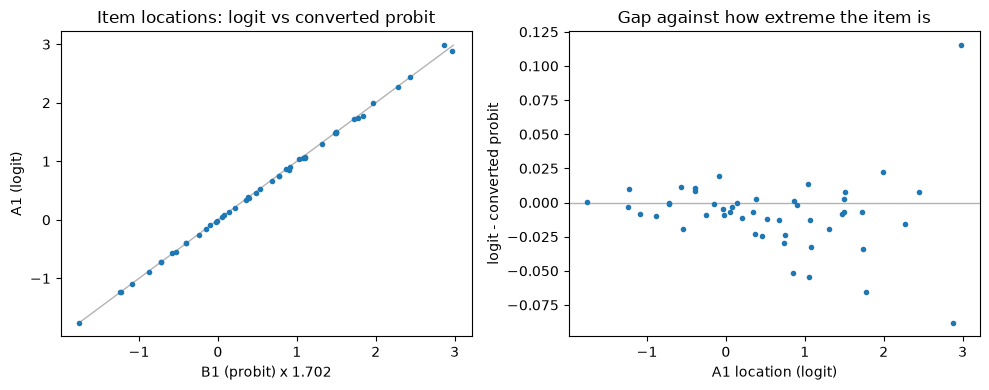

In [31]:
bnames = [f"b_{r}_{i + 1}" for r in (1, 2) for i in range(len(ITEMS))]
items_link = pd.DataFrame({"logit A1": s_A1.loc[bnames, "mean"].to_numpy(),
                           "probit B1 x 1.702": lg_B1.loc[bnames, "mean"].to_numpy(),
                           "node": [1] * len(ITEMS) + [2] * len(ITEMS)}, index=bnames)
items_link["gap"] = items_link["logit A1"] - items_link["probit B1 x 1.702"]
slope = np.polyfit(fit_B1.summary_df().loc[bnames, "mean"], items_link["logit A1"], 1)[0]
print(f"empirical scaling factor (logit on probit locations): {slope:.3f}   (1.702 assumed)")
print(f"mean |gap| = {items_link['gap'].abs().mean():.3f}, max |gap| = {items_link['gap'].abs().max():.3f}")
print(f"correlation of |gap| with |logit location|: "
      f"{np.corrcoef(items_link['gap'].abs(), items_link['logit A1'].abs())[0, 1]:.2f}")

# the same on the lme4 fits: a property of the links, not of irtree
l_logit = -lme4["A1"].loc[[f"item{it}:node{NODE[r]}" for r in (1, 2) for it in ITEMS], "estimate"].to_numpy()
l_probit = -lme4["B1"].loc[[f"item{it}:node{NODE[r]}" for r in (1, 2) for it in ITEMS], "estimate"].to_numpy()
print(f"lme4: empirical scaling factor {np.polyfit(l_probit, l_logit, 1)[0]:.3f}, "
      f"mean |logit - 1.702 probit| = {np.abs(l_logit - 1.702 * l_probit).mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
scatter(items_link, "Item locations: logit vs converted probit", axes[0],
        x="probit B1 x 1.702", y="logit A1", xlabel="B1 (probit) x 1.702", ylabel="A1 (logit)")
axes[1].axhline(0, color="0.7", lw=1)
axes[1].plot(items_link["logit A1"], items_link["gap"], "o", ms=3)
axes[1].set_xlabel("A1 location (logit)"); axes[1].set_ylabel("logit - converted probit")
axes[1].set_title("Gap against how extreme the item is")
fig.tight_layout(); fig.savefig(RESULTS / "probit_vs_logit.png", dpi=200)
items_link.round(3).to_csv(RESULTS / "probit_vs_logit_items.csv")

**Read.** The correlation should agree to Monte Carlo error. The empirical scaling factor shows how well 1.702 fits these data; a value above 1.702 means the logit locations are spread more than the converted probit ones, as expected when items sit in the tails. If the gap grows with the item's location in both irtree and lme4, the departure is a property of the links, not of either program. Conclusion for the paper: scale-free quantities (correlations, the sign and significance of effects, the ordering of items) are equivalent across links; quantities with units (locations, variances, coefficients) are equivalent after conversion to within the gap shown here, best for items near the middle.

## Step 8: Speed
Wall time includes warm-up and all chains (run in parallel). Effective samples per second use the smallest bulk ESS among the structural parameters, the quantity that decides how long a run must be. lme4 returns a point estimate and standard errors, not a posterior; its row is the time to that estimate. brms rows appear if `../capabilities/check_brms.qmd` has been run (its Part 2).

In [32]:
speed = pd.DataFrame(RUNS)
lme4_rt = pd.read_csv(RESULTS / "lme4_runtime_61.csv")
lme4_rt = pd.DataFrame({"model": lme4_rt["model"], "software": "lme4", "chains": np.nan,
                        "seconds": lme4_rt["seconds"].round(1)})
parts = [speed, lme4_rt]
brms_file = pathlib.Path("../capabilities/results/brms_speed.csv")
if brms_file.exists():
    b = pd.read_csv(brms_file)
    parts.append(pd.DataFrame({"model": b["model"], "software": "brms", "chains": b["chains"],
                               "iterations": b["iter"], "seconds": b["total_seconds"],
                               "min_ess_structural": b["min_ess_bulk_structural"],
                               "ess_per_second": (b["min_ess_bulk_structural"] / b["total_seconds"]).round(1)}))
speed_table = pd.concat(parts, ignore_index=True)
speed_table.to_csv(RESULTS / "speed_61.csv", index=False)
speed_table

,model,software,chains,iterations,draws,seconds,min_ess_structural,ess_per_second
0,A1,irtree,1.0,4000.0,3600.0,19.5,209.0,10.7
1,B1,irtree,1.0,4000.0,3600.0,11.2,336.0,29.9
2,A2,irtree,1.0,4000.0,3600.0,39.2,256.0,6.5
3,B2,irtree,1.0,4000.0,3600.0,21.8,245.0,11.2
4,"lme4 B2 (probit, covariates)",lme4,NaN,NaN,NaN,14.5,NaN,NaN
5,"lme4 B1 (probit, items fixed)",lme4,NaN,NaN,NaN,122.3,NaN,NaN
6,"lme4 A2 (logit, covariates)",lme4,NaN,NaN,NaN,14.0,NaN,NaN
7,"lme4 A1 (logit, items fixed)",lme4,NaN,NaN,NaN,81.0,NaN,NaN


**Read.** Compare like with like: A1 with lme4 A1 (items fixed), A2 with lme4 A2 (random items with covariates), and probit (B) with logit (A) within irtree. For a fair single-core comparison with lme4, set `N_CHAINS = 1` and re-run Step 4.

## Step 9: Interpreting B1 and B2
B2 is the explanatory model: the person covariates explain the two traits (latent regression) and the item covariates explain the item locations (a random-effects linear logistic test model). Coefficients are on the probit scale; `to_logit()` gives them on the logistic metric. Positive person coefficients raise the probability of the branch coded 1 (admitting at node 1, affirming at node 2); positive item coefficients do the same for items with that feature. The intercept is the node's level at the average person and item.

In [33]:
B = structural(fit_B2, cols=("mean", "sd", "hdi_lo", "hdi_hi"))
B["logit mean"] = fit_B2.to_logit().loc[B.index, "mean"]
B.round(3)

,mean,sd,hdi_lo,hdi_hi,logit mean
param,,,,,
sigma2_1,0.646,0.064,0.522,0.765,1.872
sigma2_2,0.588,0.078,0.446,0.746,1.702
b.variance_1,0.166,0.057,0.075,0.276,0.482
b.variance_2,0.164,0.057,0.076,0.275,0.476
rho_1_2,0.335,0.071,0.204,0.470,0.335
beta_1_anger,0.164,0.050,0.072,0.268,0.279
beta_1_male,0.191,0.117,-0.039,0.414,0.326
beta_2_anger,0.302,0.053,0.192,0.404,0.514
beta_2_male,0.221,0.120,-0.008,0.453,0.376


In [34]:
# Plain-language reading of the coefficients whose 95% HDI excludes 0
names = {"anger": "a higher Anger score (one SD)", "male": "being male", "intercept": "the node level",
         "scold": "scolding rather than cursing", "shout": "shouting rather than cursing",
         "self": "self-blame rather than other-blame", "do": "doing rather than wanting"}
nodes_txt = {"1": "admitting (node 1)", "2": "affirming (node 2)"}
for n, row in B.iterrows():
    p = parse_param_name(n)
    if p["kind"] in ("beta", "kappa") and p["index"] != "intercept":
        sig = "credibly" if (row["hdi_lo"] > 0 or row["hdi_hi"] < 0) else "not credibly"
        direction = "raises" if row["mean"] > 0 else "lowers"
        print(f"{names[p['index']]:36s} {direction} {nodes_txt[p['node']]:20s} "
              f"(probit {row['mean']:+.2f}, 95% HDI [{row['hdi_lo']:+.2f}, {row['hdi_hi']:+.2f}]; {sig})")

a higher Anger score (one SD)        raises admitting (node 1)   (probit +0.16, 95% HDI [+0.07, +0.27]; credibly)
being male                           raises admitting (node 1)   (probit +0.19, 95% HDI [-0.04, +0.41]; not credibly)
a higher Anger score (one SD)        raises affirming (node 2)   (probit +0.30, 95% HDI [+0.19, +0.40]; credibly)
being male                           raises affirming (node 2)   (probit +0.22, 95% HDI [-0.01, +0.45]; not credibly)
scolding rather than cursing         lowers admitting (node 1)   (probit -0.62, 95% HDI [-1.03, -0.20]; credibly)
shouting rather than cursing         lowers admitting (node 1)   (probit -1.23, 95% HDI [-1.63, -0.81]; credibly)
self-blame rather than other-blame   lowers admitting (node 1)   (probit -0.62, 95% HDI [-0.96, -0.26]; credibly)
doing rather than wanting            lowers admitting (node 1)   (probit -0.42, 95% HDI [-0.75, -0.09]; credibly)
scolding rather than cursing         lowers affirming (node 2)   (probit -0.31, 

In [35]:
# B1 against B2: how much of the trait and item variation the covariates explain
s1, s2 = fit_B1.summary_df(), fit_B2.summary_df()
pd.DataFrame({"B1 (no covariates)": s1.loc[["sigma2_1", "sigma2_2", "rho_1_2"], "mean"],
              "B2 (residual)": s2.loc[["sigma2_1", "sigma2_2", "rho_1_2"], "mean"]}).round(3)

,B1 (no covariates),B2 (residual)
param,,
sigma2_1,0.672,0.646
sigma2_2,0.687,0.588
rho_1_2,0.382,0.335


**Read.** In B2 the trait variances are residual variances given anger and gender; their drop from B1 is the share of trait variance the person covariates explain (B1's items are fixed and B2's random, so compare the trait rows, not the item rows). The correlation in B2 is between the residual traits: admission and affirmation once anger and gender are accounted for.

## Step 10: Beyond lme4: discriminations
Replacing the node models is the only change. With discriminations, a node's predictor is a(θ − b + …), not linear in its parameters, so glmer cannot fit it. On these dimensions every node now has discriminations, so the trait variances are fixed at 1 and the slopes carry the scale; the correlation is scale-free and stays estimated.

In [37]:
RUN_2PL = True
if RUN_2PL:
    nodes_2PL = [irtree.ProbitTwoPLNode(person_covariates=True, item_covariates=True),
                 irtree.ProbitTwoPLNode(person_covariates=True, item_covariates=True)]
    priors_2PL = irtree.build_default_priors(spec, nodes_2PL)
    priors_2PL.set("beta", VAGUE)
    priors_2PL.set("kappa", VAGUE)
    fit_2PL = run_fit("B2 with discriminations (2PL)", data_cov, nodes_2PL, priors_2PL, n_chains = 1)


irtree fit complete  (1 chain × 4000 iterations, 3600 posterior draws)
   parameters: 673 PASS · 74 WARN · 0 FAIL   (of 747)
   5 flagged only for under-warmup — resolve by discarding the first ~10% (recommended_burnin).
   (overall label is advisory; the per-parameter table is the decision. Call fit.diagnostics().)
   status key:
     PASS (converged): stationary with no burn-in needed, adequate mixing.
     WARN (usable, but check): at worst under-warmed (a recommended burn-in is given), OR the two stationarity tests (Geweke & Heidelberger-Welch) disagree (one passes, one flags), OR mixing/precision is marginal (low ESS, high MCSE, R-hat slightly > 1).
     FAIL (did not converge): fails BOTH stationarity tests (Geweke & Heidelberger-Welch), or R-hat exceeds its hard threshold. A parameter that passes EITHER stationarity test is a WARN, not a FAIL.
⚠  Single chain — R-hat unavailable. Stationarity via Geweke + Heidelberger-Welch.
✓ Stationarity (Geweke):   All Geweke within threshol

In [38]:
if RUN_2PL:
    s2pl = fit_2PL.summary_df()
    slopes = s2pl.loc[[n for n in s2pl.index if n.startswith("a_")], "mean"]
    print("slopes, node 1:", slopes.filter(like="a_1_").round(2).to_numpy())
    print("slopes, node 2:", slopes.filter(like="a_2_").round(2).to_numpy())
    display(pd.DataFrame({"B2 (Rasch)": s2.loc["rho_1_2", ["mean", "sd"]],
                          "2PL": s2pl.loc["rho_1_2", ["mean", "sd"]]}).round(3))

slopes, node 1: [0.72 0.89 0.81 0.81 0.92 0.76 0.55 0.87 0.57 0.69 0.97 0.58 1.01 1.38
 0.87 0.92 1.22 0.96 0.7  0.83 0.69 0.85 0.89 0.69]
slopes, node 2: [1.09 1.11 0.46 0.94 1.02 0.91 0.63 0.7  0.69 0.55 0.66 0.48 1.09 1.1
 0.66 0.75 0.88 0.81 0.6  1.   1.23 0.82 0.85 0.94]


,B2 (Rasch),2PL
mean,0.335,0.371
sd,0.071,0.068


### Compare the two trees
Approximate leave-one-out cross-validation (PSIS-LOO), leaving out one person at a time. `compare_loo(first, second)` returns `delta_elpd` = elpd(second) − elpd(first): positive favours the 2PL tree. Read it against `se_delta`.

In [39]:
if RUN_2PL:
    with timed("LOO B2 and 2PL"):
        loo_B2, loo_2PL = fit_B2.loo(), fit_2PL.loo()
    print("B2: ", loo_B2); print("2PL:", loo_2PL)
    display(irtree.compare_loo(loo_B2, loo_2PL))

[LOO B2 and 2PL] 4.0 s
B2:  LOOResult(elpd_loo=-6030.74, p_loo=538.34, se=95.46, k_warn=0/316)
2PL: LOOResult(elpd_loo=-5987.05, p_loo=563.17, se=96.35, k_warn=0/316)


{'delta_elpd': 43.699189454780935,
 'se_delta': 16.327150353284306,
 'delta_loo_ic': -87.39837890956187}

## Step 11: Report (optional)
A self-contained HTML file with the convergence table and trace plots (not committed: `irtree_report*.html` is git-ignored).

In [40]:
with timed("HTML report"):
    fit_B2.report("irtree_report_61_B2.html")

Report written to: C:\Users\mehoujm\Documents\GitHub\irtree-0.4.0\replication\verbagg\irtree_report_61_B2.html
[HTML report] 3.7 s


## Runtime

In [41]:
rt = pd.concat([pd.DataFrame(RUNS)[["model", "seconds"]].rename(columns={"model": "step"}),
                pd.DataFrame(RUNTIME)], ignore_index=True)
rt.loc[len(rt)] = {"step": "TOTAL", "seconds": rt["seconds"].sum()}
rt.to_csv(RESULTS / "runtime_61.csv", index=False)
rt

,step,seconds
0,A1,19.5
1,B1,11.2
2,A2,39.2
3,B2,21.8
4,B2 with discriminations (2PL),20.9
5,LOO B2 and 2PL,4.0
6,HTML report,3.7
7,TOTAL,120.3
